In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

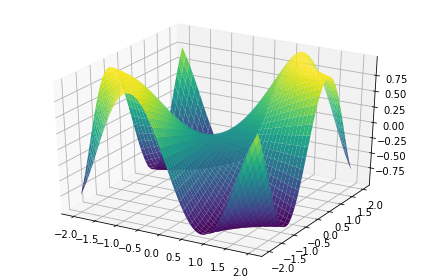

In [2]:
x, y = sp.symbols('x y')
f = sp.sin(x * y)

display_rad = 2
display_shift = 0
x_display = (x, -display_rad + display_shift, display_rad + display_shift)
y_display = (y, -display_rad + display_shift, display_rad + display_shift)

sp.plotting.plot3d(f, x_display, y_display)

In [3]:
H = sp.hessian(f, (x, y))
print(H)

Matrix([[-y**2*sin(x*y), -x*y*sin(x*y) + cos(x*y)], [-x*y*sin(x*y) + cos(x*y), -x**2*sin(x*y)]])


In [16]:
# Obtain the eigenvalues of the 2x2 hessian
eigs = H.eigenvals(multiple=True)
lamda_1 = eigs[0]
lamda_2 = eigs[1]
print(lamda_1)
print(lamda_2)

-(x**2 + y**2)*sin(x*y)/2 - sqrt(-4*x*y*sin(2*x*y) + (x**2 + y**2)**2*sin(x*y)**2 + 2*cos(2*x*y) + 2)/2
-(x**2 + y**2)*sin(x*y)/2 + sqrt(-4*x*y*sin(2*x*y) + (x**2 + y**2)**2*sin(x*y)**2 + 2*cos(2*x*y) + 2)/2


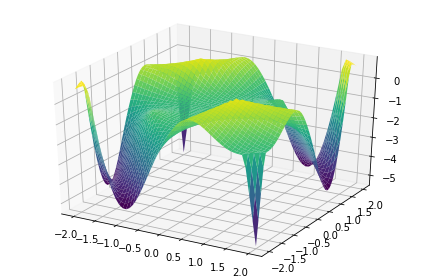

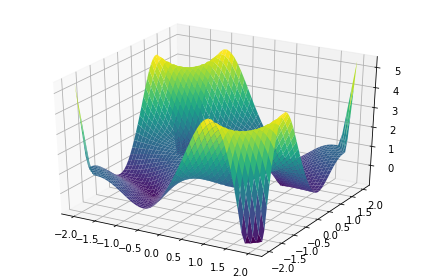

In [7]:
sp.plotting.plot3d(lamda_1, x_display, y_display)
sp.plotting.plot3d(lamda_2, x_display, y_display)

In [17]:
# Symbolically find max(lamda_i, 0) and max(-lamda_i, 0)
# algorithm: add original function to absolute value, then divide by 2
a = sp.symbols('a')
g = lambda a: sp.simplify((a + sp.Abs(a)) / 2)
h = lambda a: sp.simplify(((- a) + sp.Abs(- a)) / 2)

lamda_1_plus = g(lamda_1)
lamda_2_plus = g(lamda_2)

lamda_1_minus = h(lamda_1)
lamda_2_minus = h(lamda_2)

# sp.plotting.plot3d(lamda_1_plus, x_display, y_display)
# sp.plotting.plot3d(lamda_2_plus, x_display, y_display)
# sp.plotting.plot3d(lamda_1_minus, x_display, y_display)
# sp.plotting.plot3d(lamda_2_minus,, x_display, y_display)

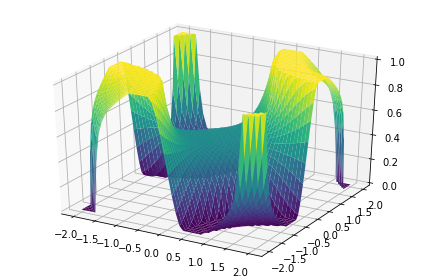

In [13]:
# The index of lack of convexity (normalized)
loc = (lamda_1_minus + lamda_2_minus) / (sp.Abs(lamda_1) + sp.Abs(lamda_2))
sp.plotting.plot3d(loc, x_display, y_display)


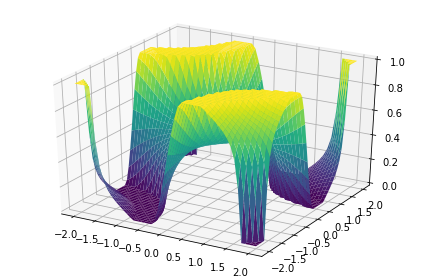

In [14]:
# index of convexity (normalized)
conv = (lamda_1_plus + lamda_2_plus) / (sp.Abs(lamda_1) + sp.Abs(lamda_2))
sp.plotting.plot3d(conv, x_display, y_display)

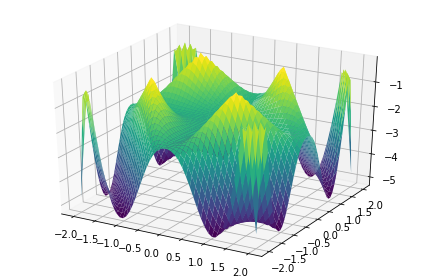

In [15]:
# places where there is only one eigenvalue
sp.plotting.plot3d(lamda_1 - lamda_2, x_display, y_display)